# 1. Reproduce ligand mutational profiles

- Preprint file, Figure 5 and abbreviated methods on pages 18–19;
- [Variant PCA](https://github.com/matthewkarlhoward/HaloTag-MOR_DMS_analysis/blob/main/shared/pca_variant_analysis.py).
- [Figure 5 panels d–f](https://github.com/matthewkarlhoward/HaloTag-MOR_DMS_analysis/blob/main/figure_05/code/pca_three_panel_variant_kde.py).
- [Position averaging](https://github.com/matthewkarlhoward/HaloTag-MOR_DMS_analysis/blob/main/shared/pca_analysis.py) and [heatmap/clustering](https://github.com/matthewkarlhoward/HaloTag-MOR_DMS_analysis/blob/main/figure_05/code/dms_stacked_heatmap_magma.R).

## 1.1 Inputs and reproducibility

In [1]:
import hashlib
import json
import platform
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import spearmanr

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (cwd, *cwd.parents)
                     if (p / "pyproject.toml").is_file()
                     and (p / "data/raw").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot locate project root.")
RAW_DATA_DIR = PROJECT_ROOT / "data/raw"
OUTPUT_DIR = PROJECT_ROOT / "results/01_reproduce_ligand_profiles"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

input_files = {
    "variants": RAW_DATA_DIR / "01_variant_scores.csv",
    "ligands": RAW_DATA_DIR / "05_ligand_summary.csv",
    "positions": RAW_DATA_DIR / "03_position_summary.csv",
}
variants = pd.read_csv(input_files["variants"], low_memory=False)
ligand_info = pd.read_csv(input_files["ligands"]).set_index("ligand")
position_reference = pd.read_csv(input_files["positions"]).set_index("position")
if variants["hgvs"].isna().any() or variants["hgvs"].duplicated().any():
    raise ValueError("Variant HGVS must be present and unique.")
if ligand_info.index.hasnans or not ligand_info.index.is_unique:
    raise ValueError("Ligand identifiers must be present and unique.")
ligands = sorted(ligand_info.index)
if len(ligands) != 15:
    raise ValueError(f"Expected 15 ligands, got {len(ligands)}.")
effect_cols = [f"{ligand}_effect" for ligand in ligands]
if not all(pd.api.types.is_numeric_dtype(variants[c]) for c in effect_cols):
    raise TypeError("Ligand effects must be numeric.")
print("Local variant table:", variants.shape)
print("Ligands:", ", ".join(ligands))
print("Output directory:", OUTPUT_DIR.relative_to(PROJECT_ROOT))

Local variant table: (10178, 106)
Ligands: Buprenorphine, Butorphanol, C6guano, Carfentanil, DAMGO, Fentanyl, MP, Methadone, Morphine, Nalbuphine, Naloxone, Naltrexone, PZM21, SR17018, TRV130
Output directory: results/01_reproduce_ligand_profiles


## 1.2 Authors' complete-case missense cohort

In [2]:
region_missense = variants.loc[
    variants["type"].eq("missense") & variants["position"].between(65, 355)
].copy()
cohort = region_missense.dropna(subset=effect_cols).set_index("hgvs")
dms_matrix = cohort[effect_cols].copy()
dms_matrix.columns = ligands
if not np.isfinite(dms_matrix.to_numpy()).all():
    raise ValueError("Non-finite effects in the PCA matrix.")
reference_pca_cols = [f"PCA_variant_PC{i}" for i in range(1, 4)]
saved_pca_ids = pd.Index(variants.loc[
    variants[reference_pca_cols].notna().all(axis=1), "hgvs"
])
cohort_summary = pd.DataFrame({
    "stage": ["All local variants", "Missense at positions 65–355",
              "Complete missense at positions 65–355", "Receptor positions"],
    "count": [len(variants), len(region_missense), len(cohort),
              cohort["position"].nunique()],
})
display(cohort_summary)
print("Exact HGVS set matches saved PCA:",
      set(cohort.index) == set(saved_pca_ids))
if dms_matrix.shape != (5519, 15) or set(cohort.index) != set(saved_pca_ids):
    raise ValueError("Local cohort does not match the authors' reference cohort.")

Exact HGVS set matches saved PCA: True


,stage,count
0,All local variants,10178
1,Missense at positions 65–355,5520
2,Complete missense at positions 65–355,5519
3,Receptor positions,291


## 1.3 Variant PCA and comparison with supplied coordinates

In [3]:
X = dms_matrix.to_numpy(dtype=float)
column_means = X.mean(axis=0)
column_sds = X.std(axis=0, ddof=0)
if np.any(column_sds == 0):
    raise ValueError("Constant ligand profile cannot be standardised.")
Z = (X - column_means) / column_sds
Z_centered = Z - Z.mean(axis=0)
U, singular_values, Vt = np.linalg.svd(Z_centered, full_matrices=False)
raw_scores = U * singular_values
raw_loadings = Vt.T * singular_values
explained_percent = 100 * singular_values**2 / np.sum(singular_values**2)

scores = pd.DataFrame(raw_scores[:, :3], index=dms_matrix.index,
                      columns=["PC1", "PC2", "PC3"])
loadings = pd.DataFrame(raw_loadings[:, :3], index=ligands,
                        columns=scores.columns)
comparison_rows = []
for pc in scores.columns:
    reference_scores = cohort[f"PCA_variant_{pc}"]
    if reference_scores.isna().any():
        raise ValueError(f"Missing reference scores for {pc}.")
    raw_r = np.corrcoef(scores[pc], reference_scores)[0, 1]
    sign = -1 if raw_r < 0 else 1
    scores[pc] *= sign
    loadings[pc] *= sign
    reference_loadings = ligand_info.loc[ligands, f"PCA_variant_loading_{pc}"]
    comparison_rows.append({
        "component": pc, "sign_applied": sign,
        "score_pearson_r": np.corrcoef(scores[pc], reference_scores)[0, 1],
        "score_rmse": np.sqrt(np.mean((scores[pc] - reference_scores)**2)),
        "score_max_abs_error": (scores[pc] - reference_scores).abs().max(),
        "loading_max_abs_error": (loadings[pc] - reference_loadings).abs().max(),
    })
pca_comparison = pd.DataFrame(comparison_rows).set_index("component")
variance_table = pd.DataFrame({
    "component": [f"PC{i}" for i in range(1, 16)],
    "explained_percent": explained_percent,
    "cumulative_percent": explained_percent.cumsum(),
})
display(variance_table.head(5))
display(pca_comparison)

np.testing.assert_allclose(raw_scores @ Vt, Z_centered, atol=1e-12)
np.testing.assert_allclose(pca_comparison["score_max_abs_error"], 0, atol=1e-10)
np.testing.assert_allclose(pca_comparison["loading_max_abs_error"], 0, atol=1e-10)
np.testing.assert_allclose(explained_percent.sum(), 100, atol=1e-10)
print("PCA reconstruction and reference checks passed.")

PCA reconstruction and reference checks passed.


,component,explained_percent,cumulative_percent
0,PC1,49.122171,49.122171
1,PC2,10.212503,59.334675
2,PC3,4.730076,64.064751
3,PC4,4.233653,68.298404
4,PC5,4.060073,72.358478


,sign_applied,score_pearson_r,score_rmse,score_max_abs_error,loading_max_abs_error
component,,,,,
PC1,1,1.0,1.029322e-15,8.881784e-15,1.278977e-13
PC2,-1,1.0,1.369686e-15,8.881784e-15,2.060574e-13
PC3,-1,1.0,5.057497e-15,3.241851e-14,4.334311e-13


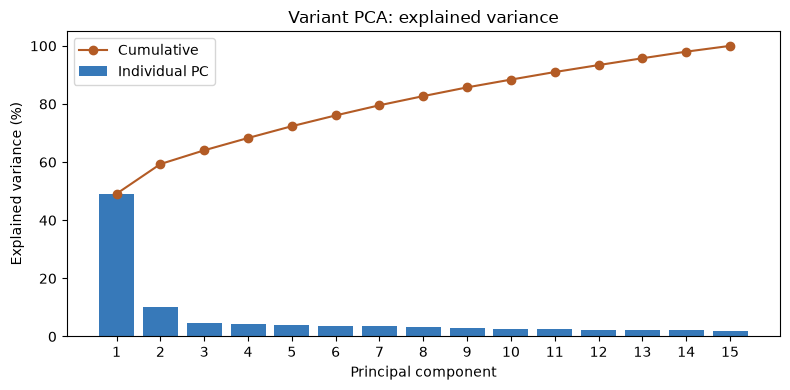

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(np.arange(1, 16), explained_percent, color="#3779b9", label="Individual PC")
ax.plot(np.arange(1, 16), explained_percent.cumsum(), "o-", color="#b35b25",
        label="Cumulative")
ax.set(xticks=np.arange(1, 16), xlabel="Principal component",
       ylabel="Explained variance (%)", title="Variant PCA: explained variance")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_pca_variance.png", dpi=160)
plt.show()

## 1.4 Surface expression and WT efficacy associations

In [5]:
surface_data = scores[["PC1"]].join(cohort[["surface_effect"]]).dropna()
efficacy_data = loadings.join(ligand_info[["tp_emax", "efficacy_class"]])
missing_emax_ligands = efficacy_data.index[efficacy_data["tp_emax"].isna()].tolist()
efficacy_complete = efficacy_data.dropna(subset=["PC2", "tp_emax"])
rho_surface = spearmanr(surface_data["PC1"], surface_data["surface_effect"]).statistic
rho_emax = spearmanr(efficacy_complete["PC2"], efficacy_complete["tp_emax"]).statistic
association_summary = pd.DataFrame({
    "comparison": ["Variant PC1 vs surface expression", "Ligand PC2 loading vs WT Emax"],
    "paired_n": [len(surface_data), len(efficacy_complete)],
    "spearman_rho": [rho_surface, rho_emax],
    "paper_reported_rho": [-0.51, -0.96],
})
association_summary["difference_from_reported"] = (
    association_summary["spearman_rho"] - association_summary["paper_reported_rho"]
)
display(association_summary)
display(efficacy_data.sort_values("tp_emax"))
print("Missing WT Emax (not imputed):", missing_emax_ligands)
print("Missing surface expression within cohort:", len(cohort) - len(surface_data))

Missing WT Emax (not imputed): ['SR17018']
Missing surface expression within cohort: 5


,comparison,paired_n,spearman_rho,paper_reported_rho,difference_from_reported
0,Variant PC1 vs surface expression,5514,-0.512391,-0.51,-0.002391
1,Ligand PC2 loading vs WT Emax,14,-0.969231,-0.96,-0.009231


,PC1,PC2,PC3,tp_emax,efficacy_class
Naloxone,-22.160302,50.020604,39.405992,14.9,antagonist
Naltrexone,-33.636265,44.580570,2.254369,15.0,antagonist
Nalbuphine,-46.681757,29.709785,-21.134402,47.0,weak
Buprenorphine,-46.534718,22.133458,-1.204023,60.2,weak
Butorphanol,-54.892704,21.232701,-13.399847,64.8,weak
MP,-45.837687,15.094976,-35.351652,65.9,weak
TRV130,-57.052067,-1.219149,-0.367515,77.2,intermediate
PZM21,-58.918025,-7.674692,8.122676,78.7,intermediate
Methadone,-57.331326,-10.728367,-4.615328,83.3,intermediate
C6guano,-56.162647,-13.203739,14.154810,88.3,strong


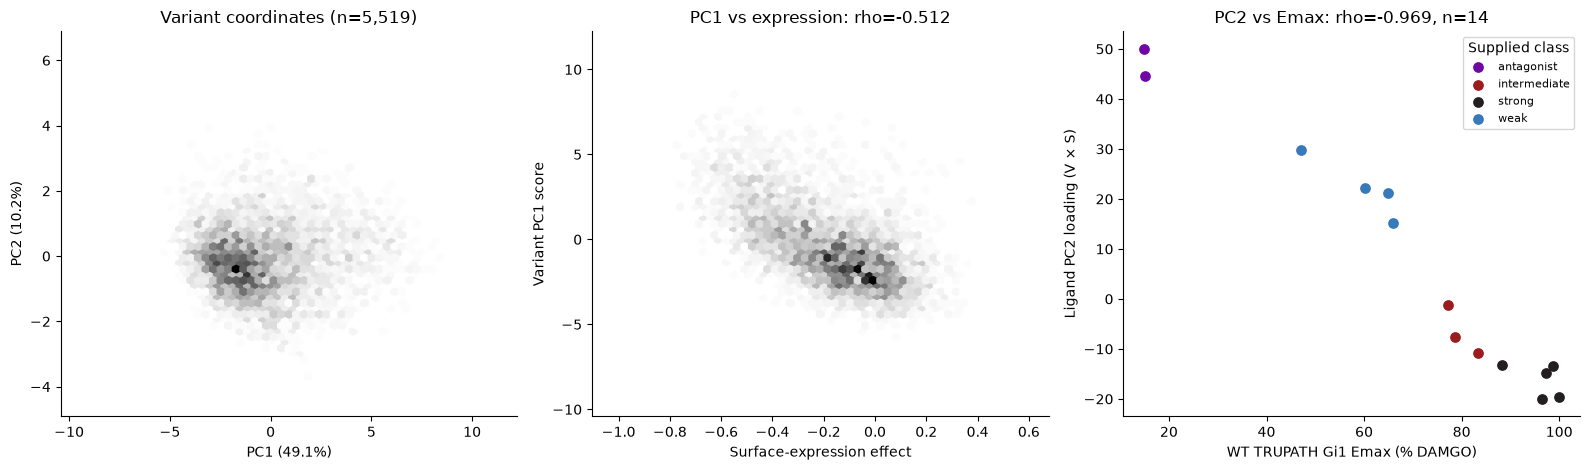

In [6]:
class_colors = {"antagonist": "#6f08a3", "weak": "#3779b9",
                "intermediate": "#9b1c1d", "strong": "#231f20"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].hexbin(scores["PC1"], scores["PC2"], gridsize=55, mincnt=1, cmap="Greys")
axes[0].set(xlabel=f"PC1 ({explained_percent[0]:.1f}%)",
            ylabel=f"PC2 ({explained_percent[1]:.1f}%)",
            title=f"Variant coordinates (n={len(scores):,})")
axes[1].hexbin(surface_data["surface_effect"], surface_data["PC1"],
               gridsize=55, mincnt=1, cmap="Greys")
axes[1].set(xlabel="Surface-expression effect", ylabel="Variant PC1 score",
            title=f"PC1 vs expression: rho={rho_surface:.3f}")
for efficacy_class, group in efficacy_complete.groupby("efficacy_class"):
    axes[2].scatter(group["tp_emax"], group["PC2"], s=45,
                    color=class_colors[efficacy_class], label=efficacy_class)
axes[2].set(xlabel="WT TRUPATH Gi1 Emax (% DAMGO)", ylabel="Ligand PC2 loading (V × S)",
            title=f"PC2 vs Emax: rho={rho_emax:.3f}, n={len(efficacy_complete)}")
axes[2].legend(title="Supplied class", fontsize=8)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_pca_expression_efficacy.png", dpi=160)
plt.show()

## 1.5 Similarity of per-position ligand profiles

In [7]:
position_profiles = dms_matrix.assign(position=cohort["position"]).groupby("position").mean()
reference_position_cols = [f"{ligand}_mean_missense_effect" for ligand in ligands]
reference_position_values = position_reference.loc[
    position_profiles.index, reference_position_cols
].to_numpy()
position_mean_max_error = np.max(np.abs(position_profiles.to_numpy() - reference_position_values))
np.testing.assert_allclose(position_profiles.to_numpy(), reference_position_values, atol=1e-12)
print("Position-profile matrix:", position_profiles.shape)
print("Maximum absolute difference from supplied position means:", position_mean_max_error)

profile_correlations = position_profiles.corr(method="pearson")
profile_distances = 1 - profile_correlations
np.testing.assert_allclose(profile_correlations, profile_correlations.T, atol=1e-12)
np.testing.assert_allclose(np.diag(profile_correlations), 1, atol=1e-12)
pair_rows = []
for i, ligand_a in enumerate(ligands):
    for ligand_b in ligands[i + 1:]:
        pair_rows.append({"ligand_a": ligand_a, "ligand_b": ligand_b,
                          "pearson_r": profile_correlations.loc[ligand_a, ligand_b],
                          "correlation_distance": profile_distances.loc[ligand_a, ligand_b]})
profile_pairs = pd.DataFrame(pair_rows).sort_values("pearson_r", ascending=False)

print("Highest profile correlations:")
display(profile_pairs.head(5).reset_index(drop=True))

print("Lowest profile correlations:")
display(profile_pairs.tail(5).sort_values("pearson_r").reset_index(drop=True))

print(f"{len(profile_pairs)} pairs share 15 ligands; these pairs are not independent.")

Position-profile matrix: (291, 15)
Maximum absolute difference from supplied position means: 1.1102230246251565e-16
Highest profile correlations:
Lowest profile correlations:
105 pairs share 15 ligands; these pairs are not independent.


,ligand_a,ligand_b,pearson_r,correlation_distance
0,DAMGO,SR17018,0.919516,0.080484
1,C6guano,Morphine,0.896629,0.103371
2,Morphine,SR17018,0.878558,0.121442
3,C6guano,PZM21,0.874443,0.125557
4,C6guano,SR17018,0.869372,0.130628


,ligand_a,ligand_b,pearson_r,correlation_distance
0,Fentanyl,Naloxone,-0.003449,1.003449
1,DAMGO,Naloxone,0.033801,0.966199
2,Naloxone,SR17018,0.036935,0.963065
3,Methadone,Naloxone,0.080473,0.919527
4,C6guano,Naloxone,0.091583,0.908417


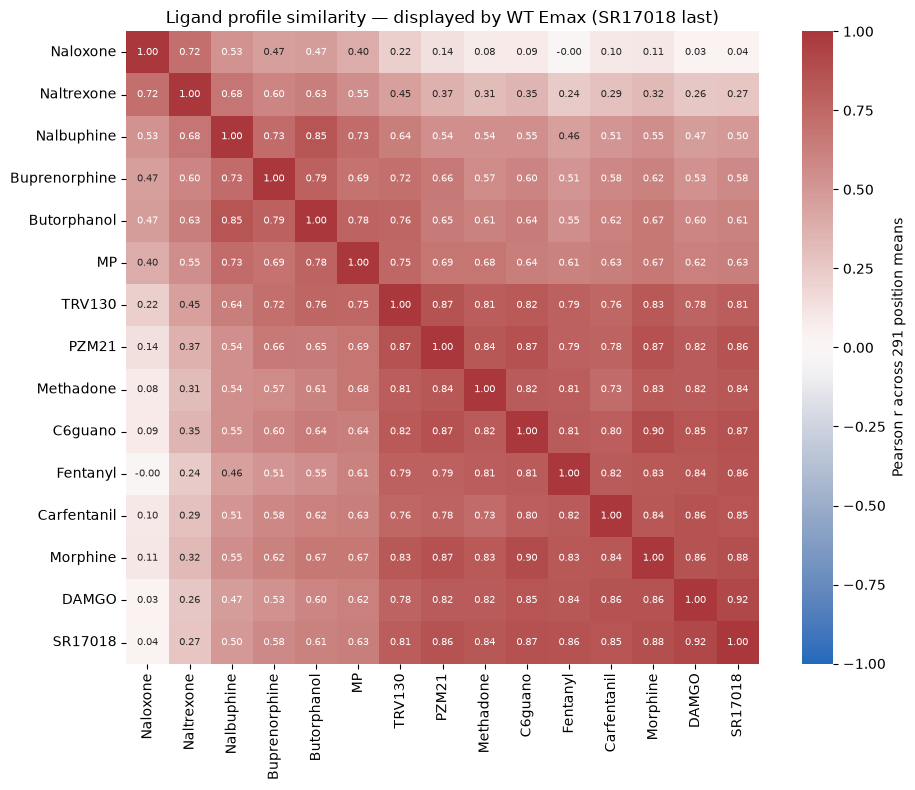

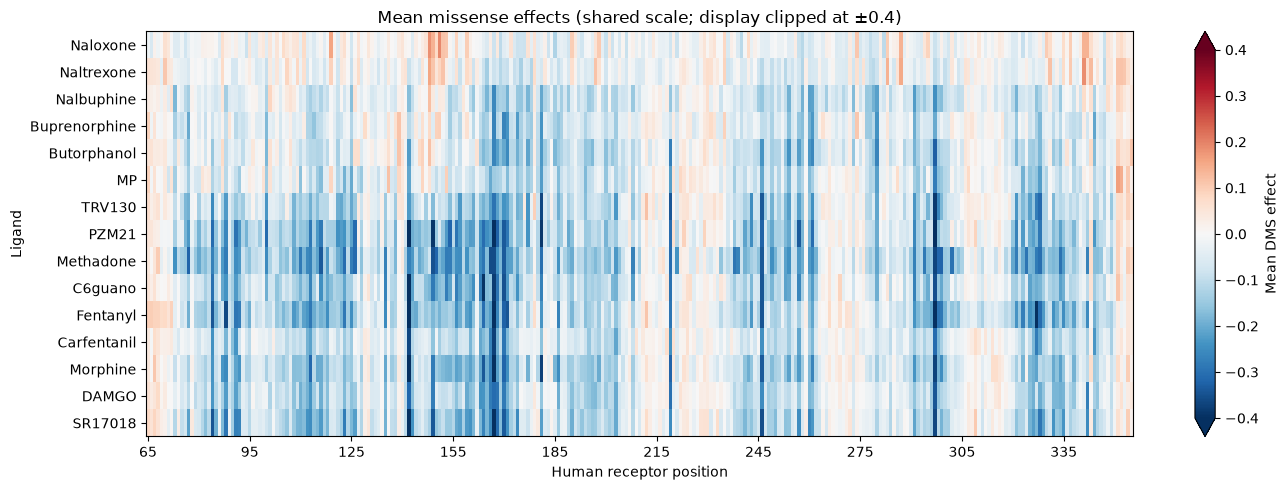

In [8]:
display_order = ligand_info.sort_values("tp_emax", na_position="last").index.tolist()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(profile_correlations.loc[display_order, display_order], ax=ax,
            cmap="vlag", vmin=-1, vmax=1, center=0, square=True,
            annot=True, fmt=".2f", annot_kws={"fontsize": 7},
            cbar_kws={"label": "Pearson r across 291 position means"})
ax.set_title("Ligand profile similarity — displayed by WT Emax (SR17018 last)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_ligand_profile_correlations.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(14, 5))
image = ax.imshow(position_profiles[display_order].T, aspect="auto", cmap="RdBu_r",
                  vmin=-0.4, vmax=0.4, interpolation="nearest")
tick_indices = np.arange(0, len(position_profiles), 30)
ax.set_xticks(tick_indices, position_profiles.index[tick_indices].astype(int))
ax.set_yticks(np.arange(len(display_order)), display_order)
ax.set(xlabel="Human receptor position", ylabel="Ligand",
       title="Mean missense effects (shared scale; display clipped at ±0.4)")
fig.colorbar(image, ax=ax, label="Mean DMS effect", extend="both")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_position_mean_effects.png", dpi=160)
plt.show()

## 1.6 Reproduction report and saved outputs

In [9]:
reproduction_report = pd.DataFrame({
    "quantity": ["Complete variants", "Positions", "PC1 variance (%)", "PC2 variance (%)",
                 "PC1 vs surface rho", "PC2 loading vs Emax rho"],
    "observed": [len(cohort), len(position_profiles), explained_percent[0],
                 explained_percent[1], rho_surface, rho_emax],
    "paper_reference": [5519, 291, 49.1, 10.2, -0.51, -0.96],
})
display(reproduction_report)
print("PC1/PC2 variance rounds to reported values:",
      np.allclose(np.round(explained_percent[:2], 1), [49.1, 10.2]))
print(f"Local 14-ligand Emax association: {rho_emax:.6f}; paper: -0.96.")
print("The Emax association is close but does not reproduce the printed coefficient exactly.")
print("Exact ligand inclusion and pharmacology version remain to be verified; "
      "no subset was selected to force agreement.")

cohort[["position", "wildtype", "mutation"]].join(scores).to_csv(OUTPUT_DIR / "variant_pca_scores.csv")
loadings.join(ligand_info[["tp_emax", "efficacy_class"]]).to_csv(OUTPUT_DIR / "ligand_pca_loadings.csv", index_label="ligand")
variance_table.to_csv(OUTPUT_DIR / "pca_explained_variance.csv", index=False)
pca_comparison.to_csv(OUTPUT_DIR / "pca_reference_comparison.csv")
association_summary.to_csv(OUTPUT_DIR / "association_summary.csv", index=False)
position_profiles.to_csv(OUTPUT_DIR / "position_mean_effects.csv")
profile_correlations.to_csv(OUTPUT_DIR / "ligand_profile_correlations.csv")
profile_distances.to_csv(OUTPUT_DIR / "ligand_profile_distances.csv")
profile_pairs.to_csv(OUTPUT_DIR / "ligand_profile_pairs.csv", index=False)
reproduction_report.to_csv(OUTPUT_DIR / "reproduction_report.csv", index=False)
manifest = {
    "inputs": {name: {"path": str(path.relative_to(PROJECT_ROOT)),
                      "sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
               for name, path in input_files.items()},
    "python": platform.python_version(),
    "packages": {package: version(package) for package in ["numpy", "pandas", "scipy", "matplotlib", "seaborn"]},
    "selection": "missense; positions 65–355 inclusive; complete 15-ligand effects",
    "pca_standardisation_ddof": 0, "loading_convention": "V * S",
    "sign_alignment": "supplied variant PCA scores, separately for PC1–3",
    "missing_emax_ligands": missing_emax_ligands,
    "scope": "Numerical Figure 5 PCA and profile-correlation reproduction; no chemistry or confirmatory tests",
}
(OUTPUT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False) + "\n")
print("Saved tables, figures and input/environment manifest to", OUTPUT_DIR.relative_to(PROJECT_ROOT))

PC1/PC2 variance rounds to reported values: True
Local 14-ligand Emax association: -0.969231; paper: -0.96.
The Emax association is close but does not reproduce the printed coefficient exactly.
Exact ligand inclusion and pharmacology version remain to be verified; no subset was selected to force agreement.
Saved tables, figures and input/environment manifest to results/01_reproduce_ligand_profiles


,quantity,observed,paper_reference
0,Complete variants,5519.000000,5519.00
1,Positions,291.000000,291.00
2,PC1 variance (%),49.122171,49.10
3,PC2 variance (%),10.212503,10.20
4,PC1 vs surface rho,-0.512391,-0.51
5,PC2 loading vs Emax rho,-0.969231,-0.96
